<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics fastapi uvicorn python-multipart requests onnx matplotlib opencv-python-headless

In [2]:
import os
import sys
import time
import json
import shutil
import subprocess
import requests
import threading

import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

PROJECT_DIR = "/content/VisionPort"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("=" * 45)
print("       VISIONPORT AI TRAFFIC SYSTEM")
print("=" * 45)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

print("Project folder:", PROJECT_DIR)
print("Environment initialised successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT AI TRAFFIC SYSTEM
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch: 2.14.1+cpu
GPU Available: False
Using CPU
Project folder: /content/VisionPort
Environment initialised successfully!


Saving traffic.jpg to traffic.jpg
Traffic image uploaded successfully!
Image dimensions: (768, 1280, 3)


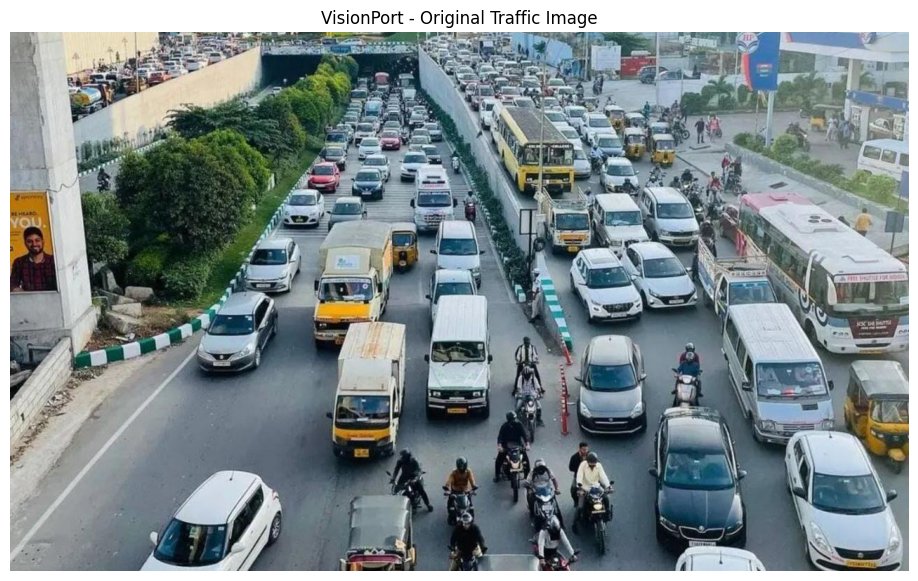

In [3]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a traffic image.")

image_name = next(iter(uploaded))

input_image = os.path.join(
    PROJECT_DIR,
    "traffic_input.jpg"
)

with open(input_image, "wb") as f:
    f.write(uploaded[image_name])

# Validate uploaded image
image = cv2.imread(input_image)

if image is None:
    raise ValueError("Invalid image. Please upload JPG or PNG.")

print("Traffic image uploaded successfully!")
print("Image dimensions:", image.shape)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("VisionPort - Original Traffic Image")
plt.axis("off")
plt.show()

In [4]:
model = YOLO("yolo11n.pt")

# Keep the model weights inside the project folder
weights_path = os.path.join(PROJECT_DIR, "yolo11n.pt")

shutil.copy2(
    model.ckpt_path,
    weights_path
)

print("YOLO11n loaded successfully!")
print("Model weights:", weights_path)
print("Model task:", model.task)
print("Number of classes:", len(model.names))

YOLO11n loaded successfully!
Model weights: /content/VisionPort/yolo11n.pt
Model task: detect
Number of classes: 80


In [5]:
device = 0 if torch.cuda.is_available() else "cpu"

start_time = time.perf_counter()

results = model.predict(
    source=input_image,
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

end_time = time.perf_counter()

inference_time = end_time - start_time

print("AI detection completed!")
print("Execution device:", device)
print("Inference time:", round(inference_time, 4), "seconds")

AI detection completed!
Execution device: cpu
Inference time: 9.9381 seconds


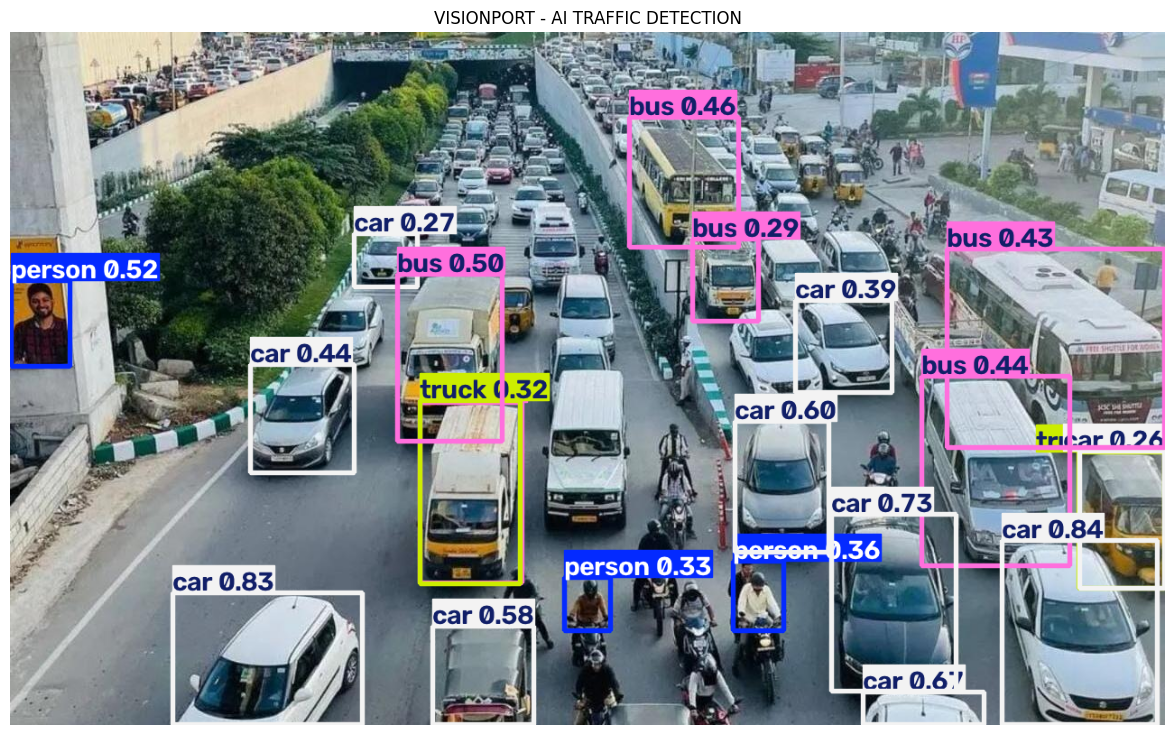

Detected image saved successfully!


In [6]:
detected_image = results[0].plot()

output_image = os.path.join(
    PROJECT_DIR,
    "traffic_ai_detected.jpg"
)

cv2.imwrite(output_image, detected_image)

plt.figure(figsize=(15, 9))

plt.imshow(
    cv2.cvtColor(detected_image, cv2.COLOR_BGR2RGB)
)

plt.title("VISIONPORT - AI TRAFFIC DETECTION")
plt.axis("off")
plt.show()

print("Detected image saved successfully!")

In [7]:
detection_report = []

boxes = results[0].boxes

if boxes is not None:
    for box in boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())

        detection_report.append({
            "object": model.names[class_id],
            "confidence": round(confidence * 100, 2)
        })

print("=" * 40)
print("       VISIONPORT DETECTION REPORT")
print("=" * 40)

for item in detection_report:
    print(
        f"{item['object']} : "
        f"{item['confidence']}%"
    )

print("\nTotal objects detected:", len(detection_report))
print("Inference time:", round(inference_time, 4), "seconds")

       VISIONPORT DETECTION REPORT
car : 83.56%
car : 82.93%
car : 72.55%
car : 67.49%
car : 59.72%
car : 58.49%
person : 52.16%
bus : 50.45%
bus : 45.69%
car : 44.05%
bus : 43.59%
bus : 43.48%
car : 39.07%
person : 36.13%
person : 32.92%
truck : 32.17%
bus : 28.73%
bus : 27.52%
car : 27.42%
car : 25.9%
truck : 25.48%

Total objects detected: 21
Inference time: 9.9381 seconds


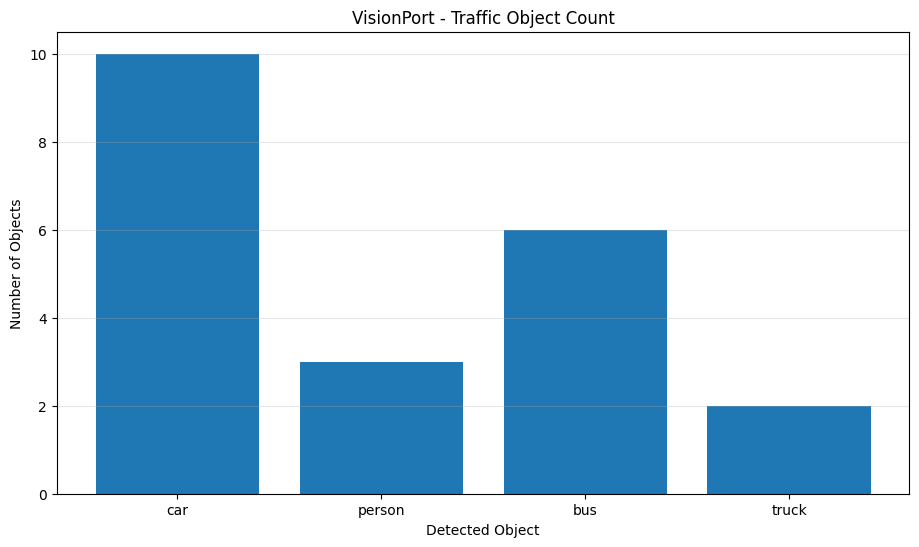

In [8]:
object_counts = Counter(
    item["object"] for item in detection_report
)

plt.figure(figsize=(11, 6))

if object_counts:
    plt.bar(
        object_counts.keys(),
        object_counts.values()
    )

plt.title("VisionPort - Traffic Object Count")
plt.xlabel("Detected Object")
plt.ylabel("Number of Objects")
plt.grid(axis="y", alpha=0.3)
plt.show()

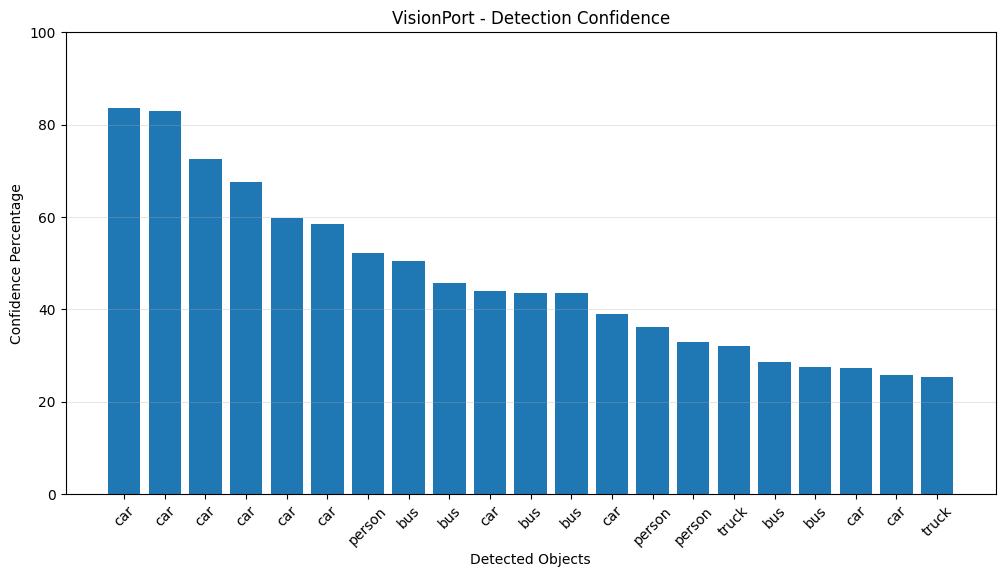

In [9]:
objects = [
    item["object"] for item in detection_report
]

confidence_scores = [
    item["confidence"] for item in detection_report
]

plt.figure(figsize=(12, 6))

if objects:
    plt.bar(
        range(len(objects)),
        confidence_scores
    )

    plt.xticks(
        range(len(objects)),
        objects,
        rotation=45
    )

plt.title("VisionPort - Detection Confidence")
plt.xlabel("Detected Objects")
plt.ylabel("Confidence Percentage")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.show()

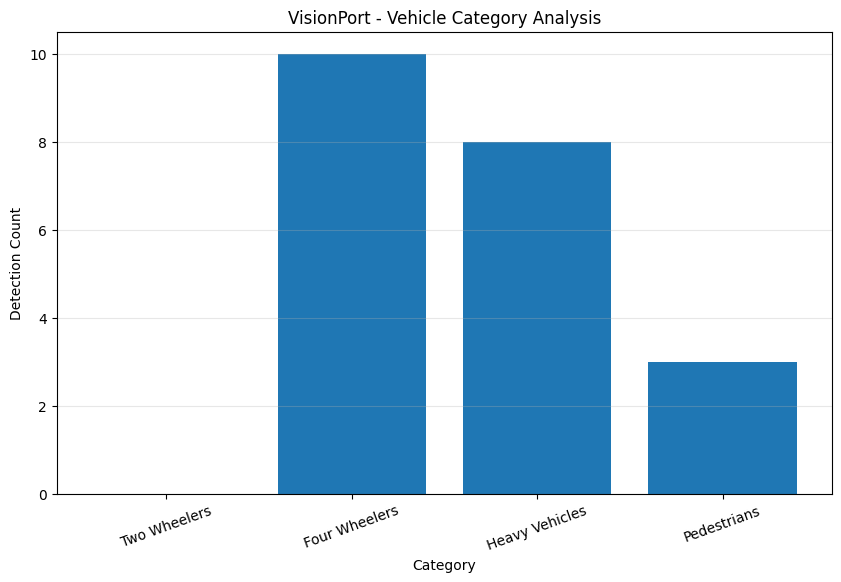

Category report: {'Two Wheelers': 0, 'Four Wheelers': 10, 'Heavy Vehicles': 8, 'Pedestrians': 3}


In [10]:
vehicle_categories = {
    "Two Wheelers": ["motorcycle", "bicycle"],
    "Four Wheelers": ["car"],
    "Heavy Vehicles": ["bus", "truck"],
    "Pedestrians": ["person"]
}

category_counts = {}

for category, classes in vehicle_categories.items():

    category_counts[category] = sum(
        1 for item in detection_report
        if item["object"] in classes
    )

plt.figure(figsize=(10, 6))

plt.bar(
    category_counts.keys(),
    category_counts.values()
)

plt.title("VisionPort - Vehicle Category Analysis")
plt.xlabel("Category")
plt.ylabel("Detection Count")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Category report:", category_counts)

VISIONPORT GPU PERFORMANCE
GPU unavailable. CPU is being used.


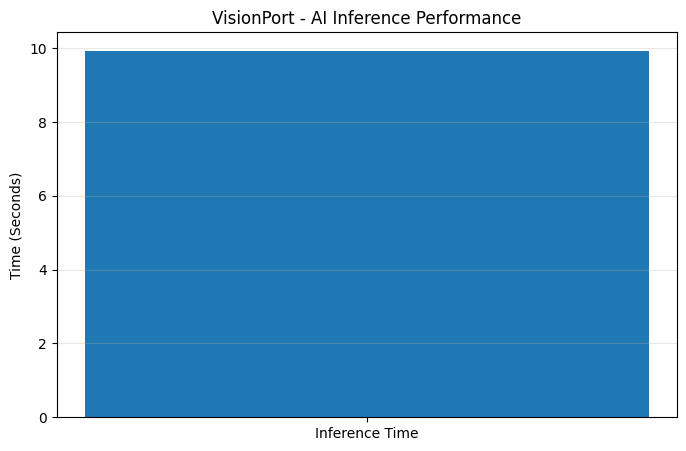

In [11]:
print("VISIONPORT GPU PERFORMANCE")

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "Memory Allocated:",
        round(torch.cuda.memory_allocated(0) / 1024**2, 2),
        "MB"
    )

    print(
        "Memory Reserved:",
        round(torch.cuda.memory_reserved(0) / 1024**2, 2),
        "MB"
    )

else:
    print("GPU unavailable. CPU is being used.")

plt.figure(figsize=(8, 5))

plt.bar(
    ["Inference Time"],
    [inference_time]
)

plt.title("VisionPort - AI Inference Performance")
plt.ylabel("Time (Seconds)")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [12]:
onnx_path = model.export(
    format="onnx",
    imgsz=640,
    dynamic=False,
    simplify=False,
    opset=17
)

onnx_destination = os.path.join(
    PROJECT_DIR,
    "visionport_model.onnx"
)

if os.path.abspath(onnx_path) != os.path.abspath(onnx_destination):
    shutil.copy2(onnx_path, onnx_destination)

print("ONNX export completed!")
print("Saved at:", onnx_destination)
print("File size:", round(os.path.getsize(onnx_destination) / 1024**2, 2), "MB")

Ultralytics 8.4.211 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from 'yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.4 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 1.4s, saved as 'yolo11n.onnx' (10.2 MB)

Export complete (1.9s)
Results saved to /content/yolo11n.onnx
Predict:         yolo predict task=detect model=yolo11n.onnx imgsz=640 
Validate:        yolo val task=detect model=yolo11n.onnx imgsz=640  
Visualize:       https://netron.app
ONNX export completed!
Saved at: /content/VisionPort/visionport_model.onnx
File size: 10.21 MB


In [13]:
import onnx

onnx_model = onnx.load(onnx_destination)

onnx.checker.check_model(onnx_model)

print("ONNX model validation successful!")

print("\nMODEL INPUTS")

for tensor in onnx_model.graph.input:
    dims = [
        d.dim_value if d.dim_value else -1
        for d in tensor.type.tensor_type.shape.dim
    ]
    print(tensor.name, dims)

print("\nMODEL OUTPUTS")

for tensor in onnx_model.graph.output:
    dims = [
        d.dim_value if d.dim_value else -1
        for d in tensor.type.tensor_type.shape.dim
    ]
    print(tensor.name, dims)

ONNX model validation successful!

MODEL INPUTS
images [1, 3, 640, 640]

MODEL OUTPUTS
output0 [1, 84, 8400]


In [14]:
def get_tensor_config(tensor):
    dims = [
        d.dim_value if d.dim_value else -1
        for d in tensor.type.tensor_type.shape.dim
    ]

    return f'''
  {{
    name: "{tensor.name}"
    data_type: TYPE_FP32
    dims: [ {", ".join(map(str, dims))} ]
  }}'''

inputs_config = ",\n".join(
    get_tensor_config(t)
    for t in onnx_model.graph.input
)

outputs_config = ",\n".join(
    get_tensor_config(t)
    for t in onnx_model.graph.output
)

triton_folder = os.path.join(
    PROJECT_DIR,
    "triton_repository",
    "visionport_yolo",
    "1"
)

os.makedirs(triton_folder, exist_ok=True)

shutil.copy2(
    onnx_destination,
    os.path.join(triton_folder, "model.onnx")
)

triton_config = f'''
name: "visionport_yolo"
platform: "onnxruntime_onnx"
max_batch_size: 0

input [
{inputs_config}
]

output [
{outputs_config}
]

instance_group [
  {{
    count: 1
    kind: KIND_GPU
  }}
]
'''

config_file = os.path.join(
    PROJECT_DIR,
    "triton_repository",
    "visionport_yolo",
    "config.pbtxt"
)

with open(config_file, "w") as f:
    f.write(triton_config)

print("Triton repository prepared!")
print(triton_config)

Triton repository prepared!

name: "visionport_yolo"
platform: "onnxruntime_onnx"
max_batch_size: 0

input [

  {
    name: "images"
    data_type: TYPE_FP32
    dims: [ 1, 3, 640, 640 ]
  }
]

output [

  {
    name: "output0"
    data_type: TYPE_FP32
    dims: [ 1, 84, 8400 ]
  }
]

instance_group [
  {
    count: 1
    kind: KIND_GPU
  }
]



In [15]:
import importlib.util

print("VISIONPORT TENSORRT CHECK")

if not torch.cuda.is_available():
    print("TensorRT requires a compatible NVIDIA GPU.")

elif importlib.util.find_spec("tensorrt") is None:
    print("TensorRT is not installed in this runtime.")
    print("Use the ONNX model for this Colab demonstration.")

else:
    try:
        engine_path = model.export(
            format="engine",
            imgsz=640,
            half=True,
            device=0
        )

        print("TensorRT conversion successful!")
        print("Engine:", engine_path)

    except Exception as error:
        print("TensorRT conversion could not complete.")
        print(str(error)[:1500])

VISIONPORT TENSORRT CHECK
TensorRT requires a compatible NVIDIA GPU.


In [17]:
%%writefile /content/VisionPort/app.py

from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import FileResponse
from ultralytics import YOLO
import cv2
import os
import uuid
import numpy as np

app = FastAPI(
    title="VisionPort AI Traffic Detection",
    description="End-to-End AI Traffic Detection API",
    version="1.0"
)

BASE_DIR = "/content/VisionPort"

MODEL_PATH = os.path.join(BASE_DIR, "yolo11n.pt")

OUTPUT_DIR = os.path.join(BASE_DIR, "api_outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

model = YOLO(MODEL_PATH)

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLO11n"
    }

@app.post("/detect")
async def detect_traffic(file: UploadFile = File(...)):

    if file.content_type not in ["image/jpeg", "image/png", "image/webp"]:
        raise HTTPException(400, "Upload a JPG, PNG or WEBP image.")

    image_bytes = await file.read()

    image_array = np.frombuffer(
        image_bytes,
        dtype=np.uint8
    )

    image = cv2.imdecode(
        image_array,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise HTTPException(400, "Invalid image.")

    results = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=0 if __import__("torch").cuda.is_available() else "cpu",
        verbose=False
    )

    annotated = results[0].plot()

    filename = "detected_" + uuid.uuid4().hex + ".jpg"

    output_path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    cv2.imwrite(output_path, annotated)

    detections = []

    if results[0].boxes is not None:

        for box in results[0].boxes:

            class_id = int(box.cls[0].item())

            confidence = float(box.conf[0].item())

            detections.append({
                "object": model.names[class_id],
                "confidence": round(confidence * 100, 2)
            })

    return {
        "project": "VisionPort",
        "status": "Detection completed",
        "total_objects": len(detections),
        "detections": detections,
        "image_url": "/image/" + filename
    }

@app.get("/image/{filename}")
def get_image(filename: str):

    if not filename.startswith("detected_") or not filename.endswith(".jpg"):
        raise HTTPException(400, "Invalid filename.")

    path = os.path.join(OUTPUT_DIR, filename)

    if not os.path.isfile(path):
        raise HTTPException(404, "Image not found.")

    return FileResponse(path, media_type="image/jpeg")

Writing /content/VisionPort/app.py


In [18]:
import subprocess
import time
import requests
import os
import sys

# Stop an older VisionPort server if one exists
if "api_process" in globals():
    if api_process.poll() is None:
        api_process.terminate()
        api_process.wait()

log_file = open(
    os.path.join(PROJECT_DIR, "fastapi.log"),
    "w"
)

api_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "app:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=PROJECT_DIR,
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Check server startup
for attempt in range(30):

    if api_process.poll() is not None:
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=2
        )

        if response.status_code == 200:
            print("VISIONPORT FASTAPI STARTED!")
            print(response.json())
            break

    except requests.exceptions.RequestException:
        time.sleep(1)

else:
    pass

if api_process.poll() is not None or not requests.get(
    "http://127.0.0.1:8000/",
    timeout=5
).ok:
    log_file.flush()
    with open(os.path.join(PROJECT_DIR, "fastapi.log")) as f:
        print(f.read())
    raise RuntimeError("FastAPI startup failed.")

VISIONPORT FASTAPI STARTED!
{'project': 'VisionPort', 'status': 'Running', 'model': 'YOLO11n'}


In [19]:
with open(input_image, "rb") as image_file:

    response = requests.post(
        "http://127.0.0.1:8000/detect",
        files={
            "file": (
                "traffic.jpg",
                image_file,
                "image/jpeg"
            )
        },
        timeout=120
    )

response.raise_for_status()

api_result = response.json()

print("=" * 40)
print("VISIONPORT FASTAPI DETECTION REPORT")
print("=" * 40)

print(json.dumps(api_result, indent=4))

VISIONPORT FASTAPI DETECTION REPORT
{
    "project": "VisionPort",
    "status": "Detection completed",
    "total_objects": 21,
    "detections": [
        {
            "object": "car",
            "confidence": 83.56
        },
        {
            "object": "car",
            "confidence": 82.93
        },
        {
            "object": "car",
            "confidence": 72.55
        },
        {
            "object": "car",
            "confidence": 67.49
        },
        {
            "object": "car",
            "confidence": 59.72
        },
        {
            "object": "car",
            "confidence": 58.49
        },
        {
            "object": "person",
            "confidence": 52.16
        },
        {
            "object": "bus",
            "confidence": 50.45
        },
        {
            "object": "bus",
            "confidence": 45.69
        },
        {
            "object": "car",
            "confidence": 44.05
        },
        {
            "objec

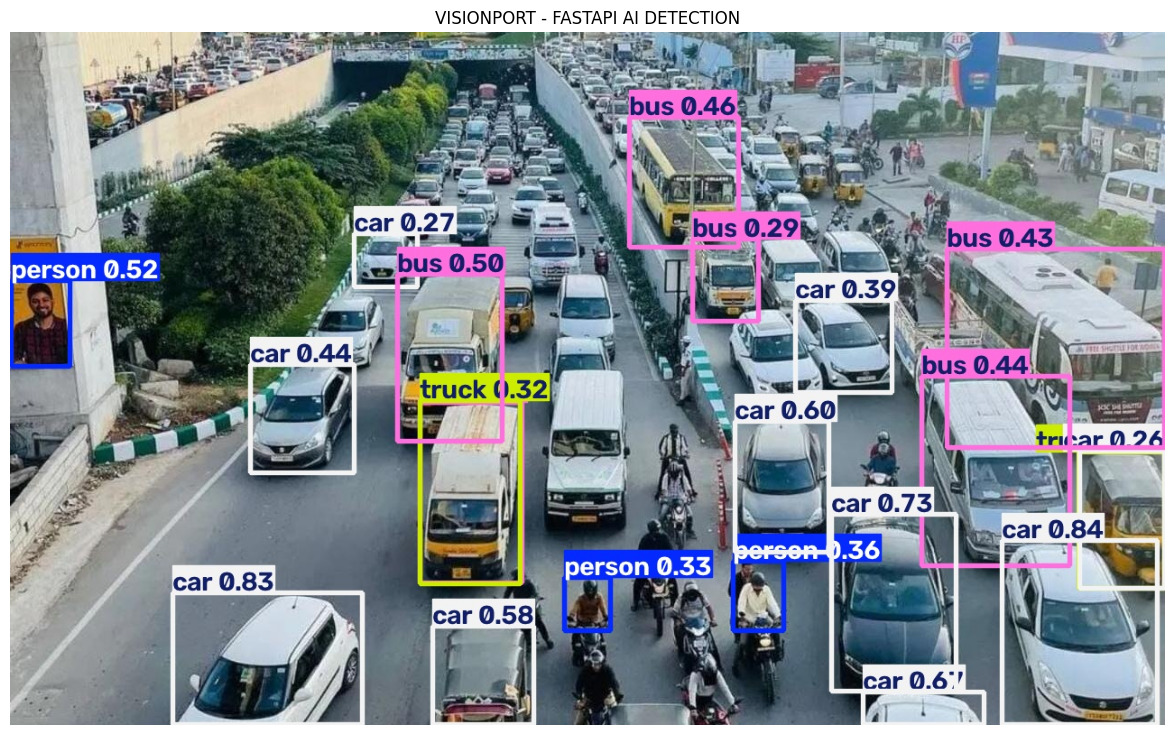

FastAPI image detection successful!


In [20]:
image_response = requests.get(
    "http://127.0.0.1:8000" + api_result["image_url"]
)

image_response.raise_for_status()

api_detected_image = cv2.imdecode(
    np.frombuffer(image_response.content, np.uint8),
    cv2.IMREAD_COLOR
)

plt.figure(figsize=(15, 9))

plt.imshow(
    cv2.cvtColor(api_detected_image, cv2.COLOR_BGR2RGB)
)

plt.title("VISIONPORT - FASTAPI AI DETECTION")

plt.axis("off")

plt.show()

print("FastAPI image detection successful!")

In [21]:
graph_folder = os.path.join(PROJECT_DIR, "graphs")

os.makedirs(graph_folder, exist_ok=True)

# Object count graph
plt.figure(figsize=(10, 6))

if object_counts:
    plt.bar(object_counts.keys(), object_counts.values())

plt.title("Traffic Object Count")
plt.xlabel("Objects")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.savefig(graph_folder + "/vehicle_count.png", bbox_inches="tight")
plt.close()

# Confidence graph
plt.figure(figsize=(10, 6))

if objects:
    plt.bar(range(len(objects)), confidence_scores)
    plt.xticks(range(len(objects)), objects, rotation=45)

plt.title("Detection Confidence")
plt.ylabel("Confidence (%)")
plt.ylim(0, 100)
plt.savefig(graph_folder + "/confidence.png", bbox_inches="tight")
plt.close()

# Category graph
plt.figure(figsize=(10, 6))
plt.bar(category_counts.keys(), category_counts.values())
plt.title("Vehicle Category Analysis")
plt.savefig(graph_folder + "/categories.png", bbox_inches="tight")
plt.close()

# Performance graph
plt.figure(figsize=(8, 5))
plt.bar(["Inference Time"], [inference_time])
plt.title("AI Inference Performance")
plt.ylabel("Seconds")
plt.savefig(graph_folder + "/performance.png", bbox_inches="tight")
plt.close()

print("All graphs saved!")

All graphs saved!


In [22]:
readme = """
VISIONPORT - END-TO-END AI TRAFFIC DETECTION

PROJECT TECHNOLOGIES:
1. Python
2. YOLO11n Deep Learning
3. OpenCV Image Processing
4. NVIDIA GPU / CUDA (when available)
5. FastAPI Backend
6. ONNX Model Export
7. TensorRT Conversion Attempt
8. Triton Model Repository Preparation
9. Matplotlib Data Visualisation

MAIN FEATURES:
- Traffic image upload
- Vehicle and pedestrian detection
- Bounding boxes
- Confidence scores
- Vehicle count analysis
- Vehicle category graphs
- AI inference performance analysis
- FastAPI image detection endpoint
- ONNX model export
- Triton deployment preparation

IMPORTANT:
TensorRT conversion and Triton server deployment
require a compatible NVIDIA GPU environment.
The Colab demo uses YOLO directly through FastAPI.
"""

with open(
    os.path.join(PROJECT_DIR, "README.txt"),
    "w"
) as f:
    f.write(readme)

requirements = """
ultralytics
fastapi
uvicorn
python-multipart
requests
onnx
opencv-python
matplotlib
"""

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w"
) as f:
    f.write(requirements)

print("Project documentation created!")

Project documentation created!


In [23]:
zip_path = shutil.make_archive(
    "/content/VisionPort_Final_Project",
    "zip",
    PROJECT_DIR
)

print("====================================")
print("VISIONPORT PROJECT COMPLETED!")
print("====================================")

print("Project ZIP:", zip_path)

print(
    "ZIP Size:",
    round(os.path.getsize(zip_path) / 1024**2, 2),
    "MB"
)

print("\nProject files:")

for root, dirs, filenames in os.walk(PROJECT_DIR):
    for filename in filenames:
        print(os.path.relpath(
            os.path.join(root, filename),
            PROJECT_DIR
        ))

VISIONPORT PROJECT COMPLETED!
Project ZIP: /content/VisionPort_Final_Project.zip
ZIP Size: 23.54 MB

Project files:
requirements.txt
app.py
traffic_input.jpg
traffic_ai_detected.jpg
fastapi.log
visionport_model.onnx
yolo11n.pt
README.txt
triton_repository/visionport_yolo/config.pbtxt
triton_repository/visionport_yolo/1/model.onnx
__pycache__/app.cpython-313.pyc
graphs/performance.png
graphs/confidence.png
graphs/vehicle_count.png
graphs/categories.png
api_outputs/detected_e107fc23234d4f6f8cf6e591ee6c51d7.jpg


In [24]:
from google.colab import files

files.download("/content/VisionPort_Final_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>